In [1]:
# Environnement
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, f1_score, ConfusionMatrixDisplay
from sklearn.pipeline import Pipeline

import kagglehub

# Jeu de données FER2013 (cache Colab)
DATASET_PATH = Path(kagglehub.dataset_download("msambare/fer2013"))
TRAIN_PATH = DATASET_PATH / "train"
TEST_PATH = DATASET_PATH / "test"

IMAGE_EXTENSIONS = (".jpg", ".jpeg", ".png")
RANDOM_STATE = 42

print("Jeu de données :", DATASET_PATH)

c:\Users\rakot\Documents\ML\Machine_Learning\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


100%|██████████| 60.3M/60.3M [00:21<00:00, 2.99MB/s]

Extracting files...


Jeu de données : C:\Users\rakot\.cache\kagglehub\datasets\msambare\fer2013\versions\1



----- Comptage des images (train) -----
angry: 3995 images
disgust: 436 images
fear: 4097 images
happy: 7215 images
neutral: 4965 images
sad: 4830 images
surprise: 3171 images

----- Exemples d'images -----


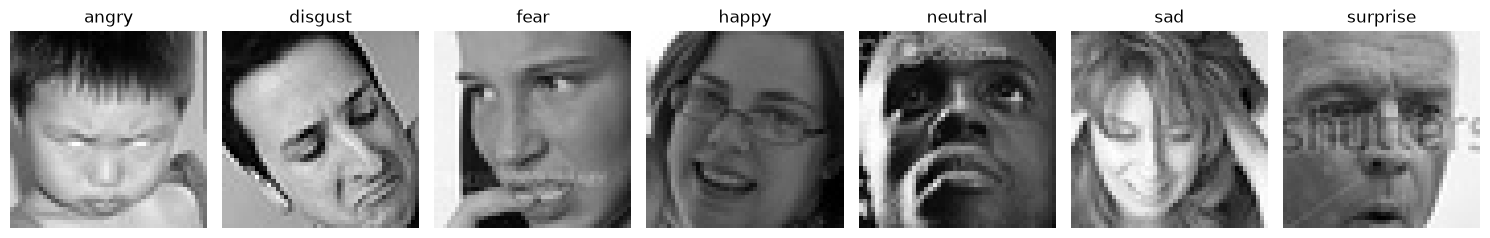


----- Distribution des émotions -----


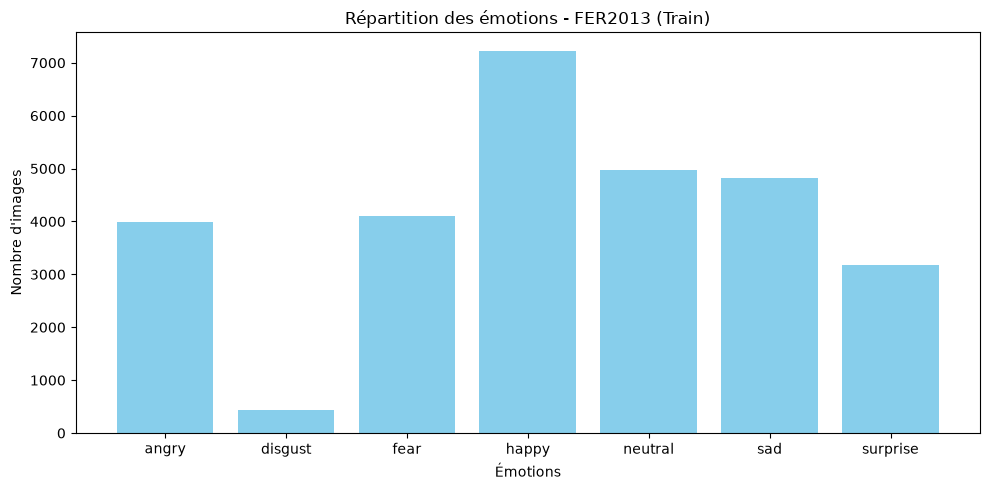


----- Chargement du jeu d'entraînement -----

Chargement terminé !
Dimensions de X : (28709, 48, 48)
Dimensions de y : (28709,)


In [2]:
# M01: Exploration des données

def list_emotion_folders(dataset_path):
    return [folder for folder in sorted(dataset_path.iterdir()) if folder.is_dir()]


def list_images(emotion_folder):
    return [file for file in sorted(emotion_folder.iterdir()) if file.suffix.lower() in IMAGE_EXTENSIONS]


# ----- Compter les images -----
def count_images(dataset_path):
    counts = {}
    for emotion_folder in list_emotion_folders(dataset_path):
        counts[emotion_folder.name] = len(list_images(emotion_folder))
        print(f"{emotion_folder.name}: {counts[emotion_folder.name]} images")
    return counts


# ----- Afficher un exemple d'image par émotion -----
def show_sample_images(dataset_path):
    emotion_folders = list_emotion_folders(dataset_path)

    fig, axes = plt.subplots(1, len(emotion_folders), figsize=(15, 3))
    for ax, emotion_folder in zip(axes, emotion_folders):
        with Image.open(list_images(emotion_folder)[0]) as image:
            ax.imshow(image.convert("L"), cmap="gray")
        ax.set_title(emotion_folder.name)
        ax.axis("off")

    plt.tight_layout()
    plt.show()


# ----- Visualiser la distribution des émotions -----
def plot_emotion_distribution(counts):
    plt.figure(figsize=(10, 5))
    plt.bar(counts.keys(), counts.values(), color="skyblue")
    plt.title("Répartition des émotions - FER2013 (Train)")
    plt.xlabel("Émotions")
    plt.ylabel("Nombre d'images")
    plt.tight_layout()
    plt.show()


# ----- Charger les images et leurs étiquettes -----
def load_dataset(dataset_path):
    images = []
    labels = []

    for emotion_folder in list_emotion_folders(dataset_path):
        for image_path in list_images(emotion_folder):
            with Image.open(image_path) as image:
                images.append(np.array(image.convert("L")))
            labels.append(emotion_folder.name)

    images = np.array(images)
    labels = np.array(labels)

    print("\nChargement terminé !")
    print("Dimensions de X :", images.shape)
    print("Dimensions de y :", labels.shape)
    return images, labels


print("\n----- Comptage des images (train) -----")
counts = count_images(TRAIN_PATH)

print("\n----- Exemples d'images -----")
show_sample_images(TRAIN_PATH)

print("\n----- Distribution des émotions -----")
plot_emotion_distribution(counts)

print("\n----- Chargement du jeu d'entraînement -----")
train_images, train_labels = load_dataset(TRAIN_PATH)

In [3]:
# M02: Préparation des données

# Dossier train: 20 % pour la validation, 80 % pour l'apprentissage
VALIDATION_SIZE = 0.2


# ----- Normalisation -----
def to_features(images):
    return images.reshape(len(images), -1).astype(np.float32) / 255


print("\n----- Chargement du jeu de test -----")
test_images, y_test = load_dataset(TEST_PATH)  # M01

print("\n----- Séparation apprentissage / validation -----")
X_train, X_val, y_train, y_val = train_test_split(
    to_features(train_images), train_labels,  # M01
    test_size=VALIDATION_SIZE, stratify=train_labels, random_state=RANDOM_STATE,
)
X_test = to_features(test_images)

print("Ensemble d'apprentissage :", X_train.shape)
print("Ensemble de validation :", X_val.shape)
print("Ensemble de test :", X_test.shape)


----- Chargement du jeu de test -----

Chargement terminé !
Dimensions de X : (7178, 48, 48)
Dimensions de y : (7178,)

----- Séparation apprentissage / validation -----
Ensemble d'apprentissage : (22967, 2304)
Ensemble de validation : (5742, 2304)
Ensemble de test : (7178, 2304)



----- Réduction de dimensionnalité avec PCA -----
X_train : (22967, 100)
X_val : (5742, 100)
X_test : (7178, 100)
Variance expliquée : 0.897526


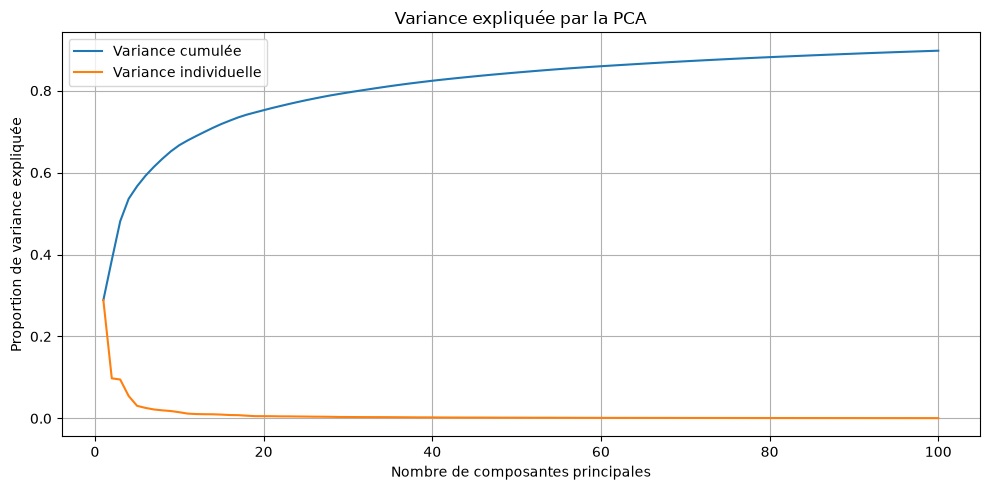

In [4]:
# M03 : Réduction de dimensionnalité avec PCA

N_COMPONENTS = 100

def apply_pca(X_train, X_val, X_test):
    # Appliquer la PCA sur les données d'entraînement
    pca = PCA(n_components=N_COMPONENTS, random_state=RANDOM_STATE)

    X_train_pca = pca.fit_transform(X_train)
    X_val_pca = pca.transform(X_val)
    X_test_pca = pca.transform(X_test)

    return X_train_pca, X_val_pca, X_test_pca, pca


print("\n----- Réduction de dimensionnalité avec PCA -----")
X_train_pca, X_val_pca, X_test_pca, pca = apply_pca(
    X_train, X_val, X_test
)

print("X_train :", X_train_pca.shape)
print("X_val :", X_val_pca.shape)
print("X_test :", X_test_pca.shape)

print("Variance expliquée :", pca.explained_variance_ratio_.sum())


# Visualiser les variances expliquées
variance = pca.explained_variance_ratio_
variance_cumulee = np.cumsum(variance)
composantes = np.arange(1, len(variance) + 1)

plt.figure(figsize=(10, 5))

plt.plot(composantes, variance_cumulee, label="Variance cumulée")
plt.plot(composantes, variance, label="Variance individuelle")

plt.xlabel("Nombre de composantes principales")
plt.ylabel("Proportion de variance expliquée")
plt.title("Variance expliquée par la PCA")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

M03 — Analyse de la variance expliquée par la PCA
La PCA permet de réduire les 2 304 caractéristiques initiales à 100 composantes principales, tout en conservant 89,75 % de la variance des données d'entraînement.

La courbe de variance cumulée montre que les premières composantes concentrent une grande partie de l'information, tandis que les suivantes apportent une contribution progressivement plus faible.

Cette réduction permet de diminuer la dimension des données avant l'entraînement du modèle, avec une perte d'environ 10,25 % de la variance initiale.

In [5]:
# M04 : Entraînement de la régression logistique multinomiale

model = LogisticRegression(
    solver="lbfgs",
    C=1.0,
    max_iter=1000
)

model.fit(X_train_pca, y_train)

# Évaluer le modèle de base
print("\n--- Modèle de base ---")

accuracy_train = accuracy_score(y_train, model.predict(X_train_pca))
accuracy_val = accuracy_score(y_val, model.predict(X_val_pca))

print(f"Accuracy entraînement : {accuracy_train * 100:.2f} %")
print(f"Accuracy validation : {accuracy_val * 100:.2f} %")

print("\n--- Rapport de classification ---")
print(classification_report(y_val, model.predict(X_val_pca), zero_division=0))


--- Modèle de base ---
Accuracy entraînement : 37.99 %
Accuracy validation : 36.99 %

--- Rapport de classification ---
              precision    recall  f1-score   support

       angry       0.27      0.14      0.18       799
     disgust       0.14      0.01      0.02        87
        fear       0.24      0.11      0.15       820
       happy       0.43      0.70      0.53      1443
     neutral       0.37      0.35      0.36       993
         sad       0.28      0.26      0.27       966
    surprise       0.44      0.48      0.46       634

    accuracy                           0.37      5742
   macro avg       0.31      0.29      0.28      5742
weighted avg       0.34      0.37      0.34      5742



In [6]:
# M05 : Validation croisée et optimisation des hyperparamètres

# Créer un pipeline avec PCA et régression logistique
pipeline = Pipeline([
    ("pca", PCA(n_components=100, random_state=42)),
    ("model", LogisticRegression(solver="lbfgs", max_iter=1000))
])

param_grid = {
    "model__C": [0.01, 0.1, 1, 10, 100]
}

# Rechercher les meilleurs paramètres avec une validation croisée
grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    cv=5,
    scoring="f1_macro",
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print("\n--- Résultats de l'optimisation ---")
print("Meilleurs paramètres :", grid_search.best_params_)
print(f"Meilleur score F1 macro : {grid_search.best_score_:.4f}")

print("\n--- Scores de validation croisée ---")

for params, score in zip(
    grid_search.cv_results_["params"],
    grid_search.cv_results_["mean_test_score"]
):
    print(f"C = {params['model__C']} : {score:.4f}")

# Évaluer le meilleur modèle sur les données de validation
best_model = grid_search.best_estimator_

accuracy_val = accuracy_score(y_val, best_model.predict(X_val))

print("\n--- Évaluation du modèle optimisé ---")
print(f"Accuracy validation : {accuracy_val * 100:.2f} %")


--- Résultats de l'optimisation ---
Meilleurs paramètres : {'model__C': 10}
Meilleur score F1 macro : 0.2869

--- Scores de validation croisée ---
C = 0.01 : 0.2769
C = 0.1 : 0.2866
C = 1 : 0.2868
C = 10 : 0.2869
C = 100 : 0.2868

--- Évaluation du modèle optimisé ---
Accuracy validation : 37.01 %



--- Comparaison des modèles ---
F1 macro initial : 0.2816
F1 macro optimisé : 0.2819

--- Rapport de classification du modèle optimisé ---
              precision    recall  f1-score   support

       angry       0.27      0.14      0.18       799
     disgust       0.14      0.01      0.02        87
        fear       0.24      0.11      0.15       820
       happy       0.43      0.70      0.53      1443
     neutral       0.37      0.35      0.36       993
         sad       0.28      0.26      0.27       966
    surprise       0.44      0.48      0.45       634

    accuracy                           0.37      5742
   macro avg       0.31      0.29      0.28      5742
weighted avg       0.34      0.37      0.34      5742



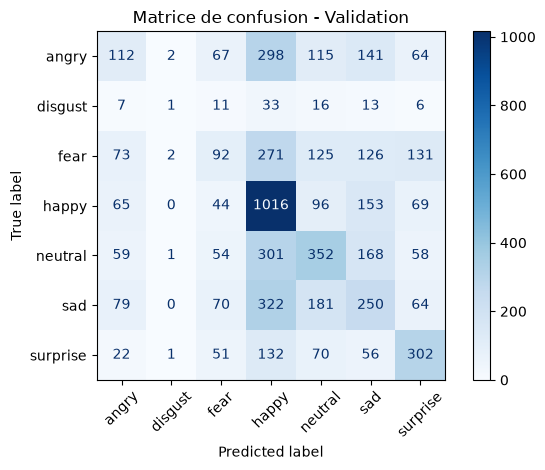

In [7]:

# M06 : Analyse des performances sur les données de validation

# Comparer les performances des deux modèles
y_pred_initial = model.predict(X_val_pca)
y_pred_optimized = best_model.predict(X_val)

f1_initial = f1_score(y_val, y_pred_initial, average="macro")
f1_optimized = f1_score(y_val, y_pred_optimized, average="macro")

print("\n--- Comparaison des modèles ---")
print(f"F1 macro initial : {f1_initial:.4f}")
print(f"F1 macro optimisé : {f1_optimized:.4f}")

# Afficher le rapport du modèle optimisé
print("\n--- Rapport de classification du modèle optimisé ---")
print(classification_report(y_val, y_pred_optimized, zero_division=0))

# Visualiser les erreurs de classification
ConfusionMatrixDisplay.from_predictions(
    y_val,
    y_pred_optimized,
    cmap="Blues",
    xticks_rotation=45
)

plt.title("Matrice de confusion - Validation")
plt.tight_layout()
plt.show()


Accuracy test : 37.89 %

--- Rapport de classification ---
              precision    recall  f1-score   support

       angry       0.25      0.13      0.17       958
     disgust       0.50      0.01      0.02       111
        fear       0.25      0.13      0.17      1024
       happy       0.44      0.71      0.54      1774
     neutral       0.35      0.34      0.35      1233
         sad       0.31      0.31      0.31      1247
    surprise       0.47      0.47      0.47       831

    accuracy                           0.38      7178
   macro avg       0.37      0.30      0.29      7178
weighted avg       0.35      0.38      0.35      7178



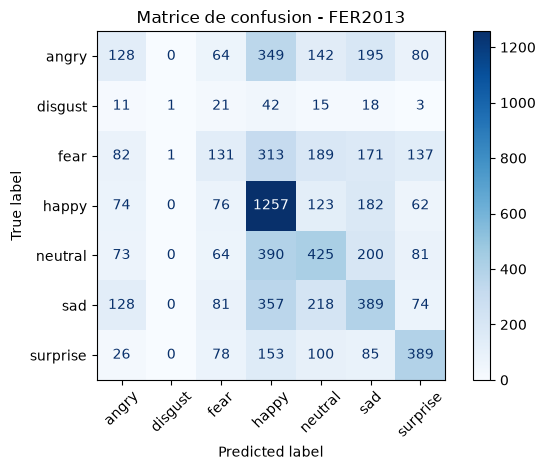

In [8]:
# M06 : Évaluation finale du modèle


# Prédictions sur les données de test
y_pred = best_model.predict(X_test)

# Précision du modèle
accuracy_test = accuracy_score(y_test, y_pred)
print(f"Accuracy test : {accuracy_test * 100:.2f} %")

# Rapport de classification
print("\n--- Rapport de classification ---")
print(classification_report(y_test, y_pred, zero_division=0))

# Matrice de confusion
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    cmap="Blues",
    xticks_rotation=45
)

plt.title("Matrice de confusion - FER2013")
plt.tight_layout()
plt.show()

M06 — Analyse des performances (Nathan)
L'évaluation finale du modèle optimisé sur les 7 178 images de test donne une accuracy de 37,87 % et un F1-score macro de 0,29.

La matrice de confusion révèle des performances inégales selon les expressions faciales. La joie (happy) est l'émotion la mieux reconnue, avec un rappel de 71 %, tandis que le dégoût (disgust) n'est pas correctement identifié.

Le modèle tend également à prédire fréquemment l'émotion happy à la place d'autres émotions, notamment fear, sad et neutral, ce qui entraîne des erreurs de classification.

L'optimisation des hyperparamètres n'a pas apporté d'amélioration notable par rapport au modèle initial. Ces résultats mettent en évidence les limites de la régression logistique pour la classification des émotions faciales et permettent d'envisager des pistes d'amélioration.